In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import tensorflow as tf
import os
from os.path import isfile, join
import numpy as np
import shutil
from tensorflow import keras
from pathlib import Path
from IPython.display import display, Audio
import subprocess

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
%matplotlib inline
import IPython as ipd
import librosa
import librosa.display
from IPython.display import Audio
import os

plt.rcParams['figure.figsize'] = (12,6)
plt.style.use('fivethirtyeight')

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from keras.utils import to_categorical
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, LSTM, Bidirectional, Input, concatenate
from keras.optimizers import Adam
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from keras.layers import Conv1D, MaxPooling1D, Dense, Dropout, LSTM

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/content/drive/MyDrive/archive/TESS Toronto emotional speech set data'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Streaming output truncated to the last 5000 lines.
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_hire_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_kite_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_gas_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_lid_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_bite_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_bought_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_five_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_jail_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_beg_sad.wav
/content/drive/MyDrive/archive/TESS Toronto emotional speech set data/YAF_sad/YAF_half_sad.wav


In [ ]:
paths = []
labels = []
for dirname, _, filenames in os.walk('/content/drive/MyDrive/TESS Toronto emotional speech set data'):
    for filename in filenames:
        paths.append(os.path.join(dirname, filename))
        label = filename.split('_')[-1]
        label = label.split('.')[0]
        labels.append(label.lower())
    if len(paths) == 2800:
        break
print('Dataset is Loaded')

Dataset is Loaded


In [ ]:
df = pd.DataFrame()
df['speech'] = paths
df['label'] = labels
df.head().style.set_properties(**{'background-color':'yellow','color':'black','border-color':'#8b8c8c'})

,speech,label


In [ ]:
df['label'].value_counts()


Series([], Name: label, dtype: int64)

In [ ]:
def waveshow(data, sr, emotion):
    plt.figure(figsize=(10,4))
    plt.title(emotion, size=20)
    librosa.display.waveshow(data, sr=sr)
    plt.show()

def spectogram(data, sr, emotion):
    x = librosa.stft(data)
    xdb = librosa.amplitude_to_db(abs(x))
    plt.figure(figsize=(11,4))
    plt.title(emotion, size=20)
    librosa.display.specshow(xdb, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()

In [ ]:
# Select an emotion
emotion = 'happy'

# Load the audio file
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)

# Display the waveform and spectrogram
waveshow(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)

# Play the audio file
Audio(path)

IndexError: index 0 is out of bounds for axis 0 with size 0

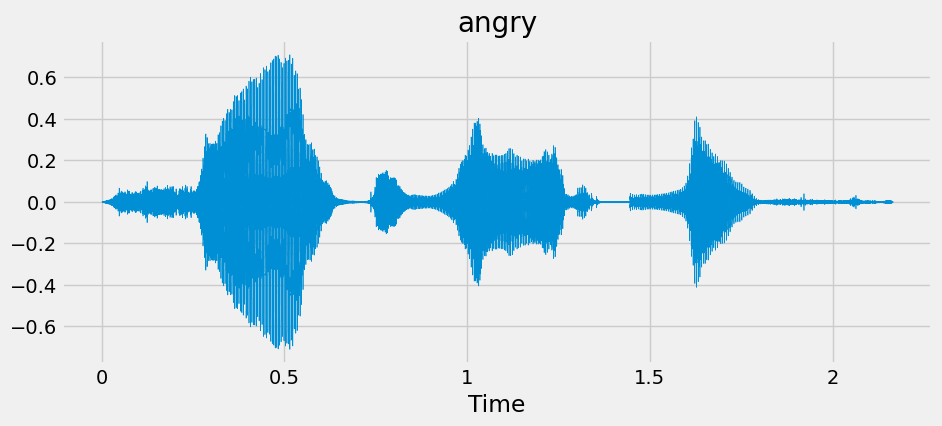

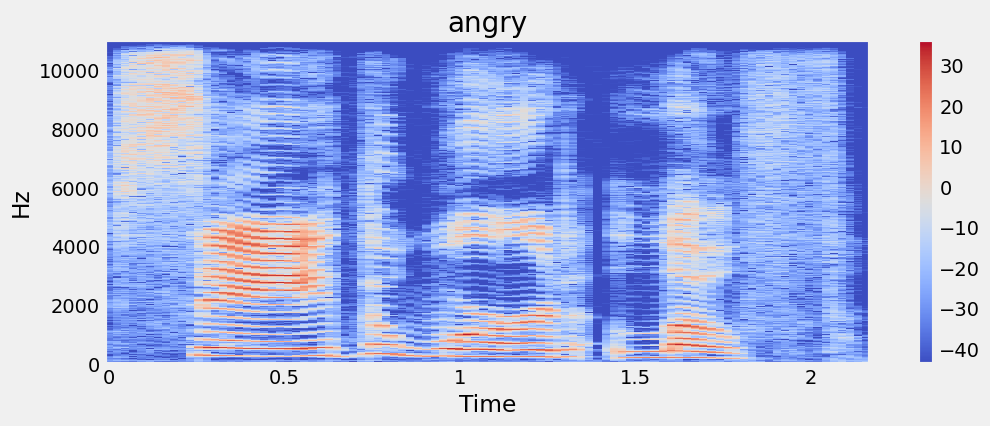

In [ ]:
# Select an emotion
emotion = 'angry'

# Load the audio file
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)

# Display the waveform and spectrogram
waveshow(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)

# Play the audio file
Audio(path)

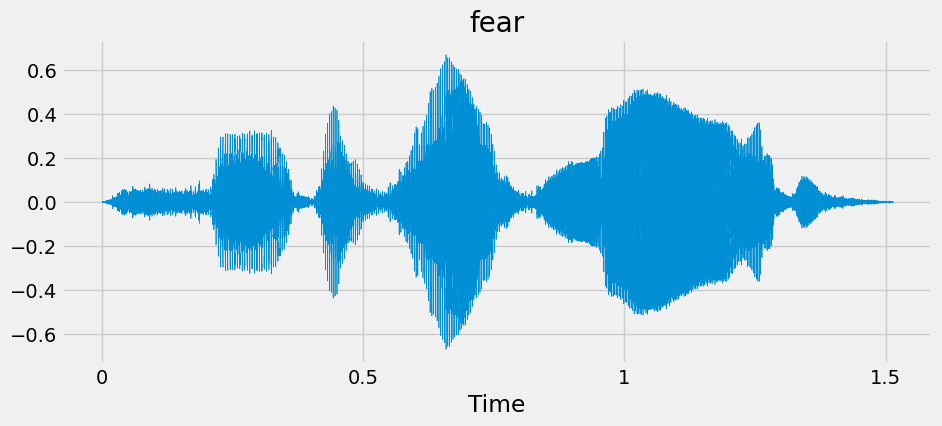

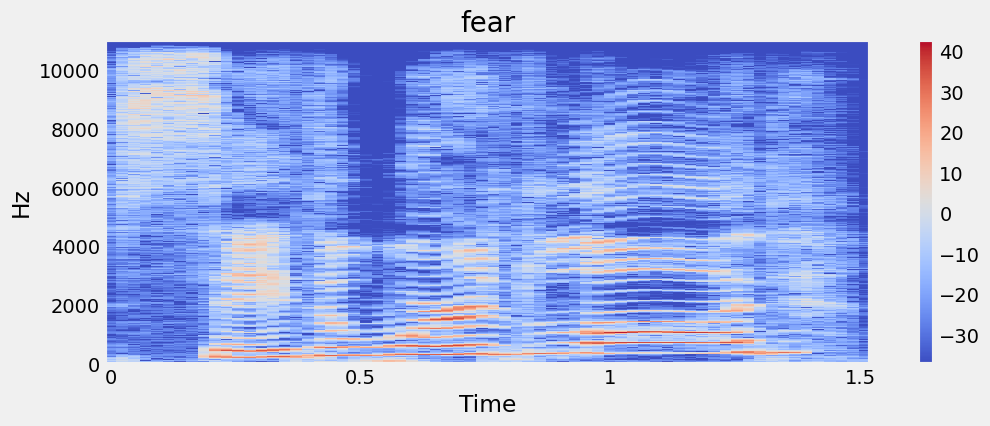

In [ ]:
# Select an emotion
emotion = 'fear'

# Load the audio file
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)

# Display the waveform and spectrogram
waveshow(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)

# Play the audio file
Audio(path)

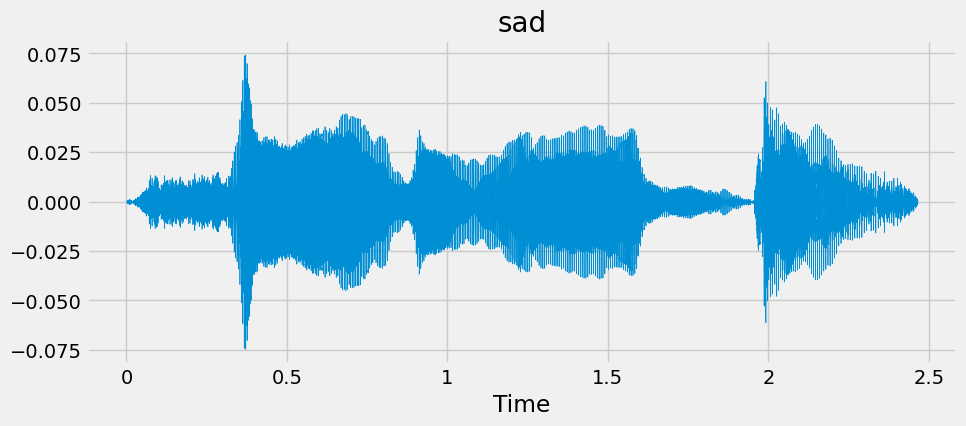

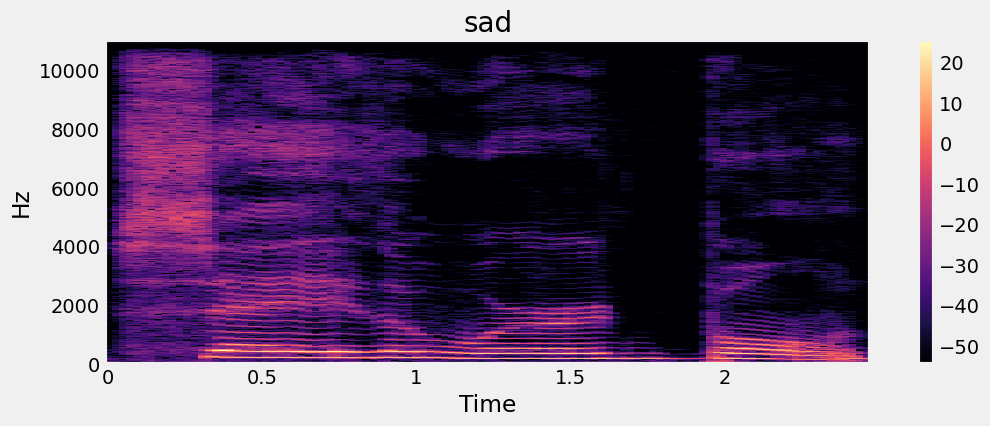

In [ ]:
# Select an emotion
emotion = 'sad'

# Load the audio file
path = np.array(df['speech'][df['label']==emotion])[0]
data, sampling_rate = librosa.load(path)

# Display the waveform and spectrogram
waveshow(data, sampling_rate, emotion)
spectogram(data, sampling_rate, emotion)

# Play the audio file
Audio(path)


In [ ]:
# compute MFCCs for each audio file
def extract_mfcc(filename):
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40).T, axis=0)
    return mfcc

In [ ]:
extract_mfcc(df['speech'][0])


array([-551.9099    ,  117.02296   ,   44.473824  ,   18.151035  ,
         16.726265  ,    5.182237  ,   -7.013134  ,   -8.812344  ,
        -17.544903  ,    0.6912341 ,  -12.803777  ,    0.64631355,
         -8.4460945 ,    2.7649932 ,    1.7288759 ,   -3.3531132 ,
          2.886218  ,   -1.5674357 ,    0.55868334,   -2.9315712 ,
          3.5014257 ,   -1.140024  ,   -6.00204   ,   -1.4016316 ,
        -10.337335  ,    3.6349878 ,   -8.01923   ,   -1.8657756 ,
         -5.2932568 ,   -3.6917298 ,   -1.8394476 ,    9.126827  ,
          2.7328937 ,   10.798426  ,    9.674865  ,    5.495597  ,
          7.89584   ,    9.538768  ,   15.272151  ,   23.69078   ],
      dtype=float32)

In [ ]:
X_mfcc = df['speech'].apply(lambda X: extract_mfcc(X))
X_mfcc

0       [-551.9099, 117.02296, 44.473824, 18.151035, 1...
1       [-521.01794, 119.734406, 28.029362, 1.2564013,...
2       [-536.6411, 93.577324, 27.457087, 25.147121, 2...
3       [-516.2354, 93.02311, 24.75125, 3.9907653, 17....
4       [-528.4611, 105.532524, 33.695126, 19.274752, ...
                              ...                        
2745    [-440.78555, 80.94026, 10.855523, -6.173477, -...
2746    [-433.29758, 79.90519, 7.0025296, -17.684155, ...
2747    [-472.0142, 63.13129, 10.757127, 3.4197447, 10...
2748    [-428.7984, 82.43286, 5.2509885, -24.473654, 3...
2749    [-415.166, 70.506, 0.73379844, -23.595888, -12...
Name: speech, Length: 2750, dtype: object

In [ ]:
X =[x for x in X_mfcc]
X = np.array(X)
X.shape

(2750, 40)

In [ ]:
X=np.expand_dims(X,-1)
X.shape

(2750, 40, 1)

In [ ]:
from sklearn.model_selection import train_test_split
from keras.utils import to_categorical
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, LSTM, Bidirectional, Input, concatenate
from keras.callbacks import ModelCheckpoint
from keras.optimizers import Adam
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from keras.layers import Conv1D, MaxPooling1D, Dense, Dropout, LSTM

In [ ]:
enc = OneHotEncoder()
y = enc.fit_transform(df[['label']])

In [ ]:
y.toarray()

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.]])

In [ ]:
y.shape

(2750, 8)

In [ ]:
# Define CNN model
model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(40,1)),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(7, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 38, 32)            128       
                                                                 
 max_pooling1d (MaxPooling1  (None, 19, 32)            0         
 D)                                                              
                                                                 
 conv1d_1 (Conv1D)           (None, 17, 64)            6208      
                                                                 
 max_pooling1d_1 (MaxPoolin  (None, 8, 64)             0         
 g1D)                                                            
                                                                 
 flatten (Flatten)           (None, 512)               0         
                                                                 
 dense (Dense)               (None, 128)               6

In [ ]:
# Define LSTM model
model = Sequential([
    LSTM(256, return_sequences=False, input_shape=(40,1)),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(7, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 256)               264192    
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_3 (Dense)             (None, 128)               32896     
                                                                 
 dropout_3 (Dropout)         (None, 128)               0         
                                                                 
 dense_4 (Dense)             (None, 64)                8256      
                                                                 
 dropout_4 (Dropout)         (None, 64)                0         
                                                                 
 dense_5 (Dense)             (None, 7)                

In [ ]:
from keras.layers import SimpleRNN
# Define RNN model

model = Sequential([
    SimpleRNN(256, return_sequences=False, input_shape=(40,1)),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(7, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 256)               66048     
                                                                 
 dropout_5 (Dropout)         (None, 256)               0         
                                                                 
 dense_6 (Dense)             (None, 128)               32896     
                                                                 
 dropout_6 (Dropout)         (None, 128)               0         
                                                                 
 dense_7 (Dense)             (None, 64)                8256      
                                                                 
 dropout_7 (Dropout)         (None, 64)                0         
                                                                 
 dense_8 (Dense)             (None, 7)                

In [ ]:
# Define hybrid model
model = Sequential()

# Add a 1D convolutional layer
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(40, 1)))

# Add a max pooling layer
model.add(MaxPooling1D(pool_size=2))

# Add a dropout layer
model.add(Dropout(0.2))

# Add an LSTM layer
model.add(LSTM(128, return_sequences=False))

# Add a dense output layer with softmax activation
model.add(Dense(7, activation='softmax'))

# Compile the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Print the model summary
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_2 (Conv1D)           (None, 38, 64)            256       
                                                                 
 max_pooling1d_2 (MaxPoolin  (None, 19, 64)            0         
 g1D)                                                            
                                                                 
 dropout_8 (Dropout)         (None, 19, 64)            0         
                                                                 
 lstm_1 (LSTM)               (None, 128)               98816     
                                                                 
 dense_9 (Dense)             (None, 7)                 903       
                                                                 
Total params: 99975 (390.53 KB)
Trainable params: 99975 (390.53 KB)
Non-trainable params: 0 (0.00 Byte)
________________

In [ ]:
rlrp = ReduceLROnPlateau(monitor='loss', factor=0.4, verbose=0, patience=2, min_lr=0.0000001)
history=model.fit(x_train, y_train, batch_size=64, epochs=50, validation_data=(x_test, y_test), callbacks=[rlrp])

NameError: name 'ReduceLROnPlateau' is not defined